# Churn EDA — Verified Analysis

**Build-stage notebook.** Every cell runs top to bottom with no manual intervention. All findings are verified against the raw data sources and reproducible via `scripts/verify_findings.py`.

**Data sources:** `data/customers.csv`, `data/transactions.db`, `data/transactions_monthly_agg.parquet`
**As-of date:** 2026-08-01  |  **Leakage cutoff:** 2026-05-03

## 1. Load All Three Sources

In [1]:
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt
import numpy as np
import os, sys
%matplotlib inline

# Navigate to project root for data file access
os.chdir(os.path.dirname(os.getcwd()) if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd())

plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['figure.dpi'] = 100

from eda.load import load_customers, load_transactions, load_monthly_agg
from eda.profile import (
    profile_schema, profile_missingness, profile_distribution,
    count_outliers_mad, count_zero_activity_customers,
)
from eda.hypotheses import (
    hypothesis_acquisition_channel, hypothesis_region, hypothesis_txn_channel, hypothesis_category,
    hypothesis_avg_monthly_spend, hypothesis_total_amount, hypothesis_return_count,
    hypothesis_days_since_last_txn,
)
from eda.time_checks import monthly_volume_trend, trend_direction, compare_row_level_vs_monthly_agg
from eda.leakage_checks import check_no_post_as_of_rows_used, flag_label_circular_drivers, get_leakage_cutoff

cust = load_customers()
txn = load_transactions()
agg = load_monthly_agg()

print('customers.csv:', cust.shape)
print('transactions.db:', txn.shape)
print('monthly_agg.parquet:', agg.shape)


customers.csv: (1500, 5)
transactions.db: (11742, 6)
monthly_agg.parquet: (8086, 5)


## 2. Schema & Dtypes

| Source | Columns |
|---|---|
| customers.csv | customer_id (int64), signup_date (datetime64), acquisition_channel (object), region (object), churned (int64) |
| transactions.db | customer_id (int64), txn_timestamp (datetime64), category (object), channel (object), amount (float64), is_returned (int64) |
| monthly_agg.parquet | customer_id (int64), txn_month (datetime64), txn_count (int64), total_amount (float64), return_count (int64) |

In [2]:
print('=== customers.csv ===')
print(cust.dtypes)
print()
print('=== transactions.db ===')
print(txn.dtypes)
print()
print('=== monthly_agg.parquet ===')
print(agg.dtypes)


=== customers.csv ===
customer_id                     int64
signup_date            datetime64[us]
acquisition_channel               str
region                            str
churned                         int64
dtype: object

=== transactions.db ===
customer_id               int64
txn_timestamp    datetime64[ns]
category                    str
channel                     str
amount                  float64
is_returned               int64
dtype: object

=== monthly_agg.parquet ===
customer_id              int64
txn_month       datetime64[us]
txn_count                int64
total_amount           float64
return_count             int64
dtype: object


## 3. Missingness Check

All three sources have **zero missing values** across all columns. No sentinel-value defects found.

In [3]:
for name, df in [('customers.csv', cust), ('transactions.db', txn), ('monthly_agg.parquet', agg)]:
    miss = profile_missingness(df)
    print(f'{name}: {miss}')
print()
print('All three sources have zero missing values.')


customers.csv: {'customer_id': 0, 'signup_date': 0, 'acquisition_channel': 0, 'region': 0, 'churned': 0}
transactions.db: {'customer_id': 0, 'txn_timestamp': 0, 'category': 0, 'channel': 0, 'amount': 0, 'is_returned': 0}
monthly_agg.parquet: {'customer_id': 0, 'txn_month': 0, 'txn_count': 0, 'total_amount': 0, 'return_count': 0}

All three sources have zero missing values.


## 4. Zero-Activity Customers

Customers in `customers.csv` with zero rows in `transactions.db`. These 81 customers represent a **separate behavioral cohort** — all are churned, and this is a definitional property, not a predictor.

In [4]:
n_zero, zero_ids = count_zero_activity_customers(cust, txn)
print(f'Zero-activity customers: {n_zero}')
print(f'Total customers: {len(cust)}')
print(f'Customers with transactions: {cust.customer_id.isin(txn.customer_id.unique()).sum()}')

df_zero = cust[cust.customer_id.isin(zero_ids)]
churned_zero = int(df_zero.churned.sum())
print(f'Churned among zero-activity: {churned_zero} / {n_zero}')
print(f'% of all churned: {n_zero / 202 * 100:.1f}%')
print()
print('By acquisition channel:')
print(df_zero.acquisition_channel.value_counts().to_dict())
print('By region:')
print(df_zero.region.value_counts().to_dict())


Zero-activity customers: 81
Total customers: 1500
Customers with transactions: 1419
Churned among zero-activity: 81 / 81
% of all churned: 40.1%

By acquisition channel:
{'organic': 35, 'referral': 20, 'paid_search': 19, 'social': 7}
By region:
{'east': 22, 'west': 20, 'south': 20, 'north': 19}


## 5. Distribution Shape & Outliers

### Transaction Amount (transactions.db)

Heavily right-skewed (log-normal shape). These are natural high-value purchases, not data errors.

Transaction Amount distribution:
  count: 11742
  mean: 49.7202
  std: 55.2401
  min: 3.0
  q25: 18.36
  median: 33.82
  q75: 61.3875
  max: 1684.21
  skew: 6.1066
MAD-based outliers (threshold=3): 1612 (13.7%)


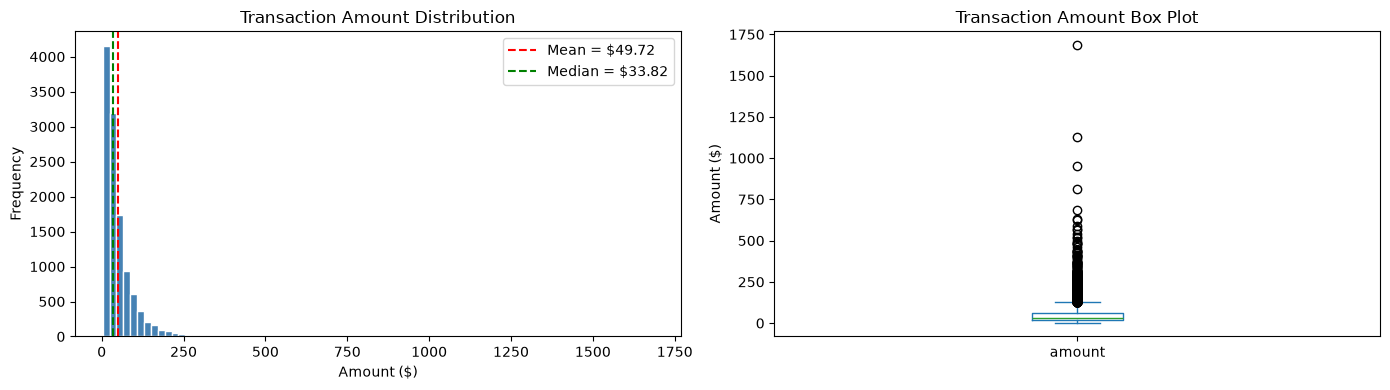

In [5]:
d = profile_distribution(txn['amount'])
print('Transaction Amount distribution:')
for k, v in d.items():
    print(f'  {k}: {v}')

n_mad = count_outliers_mad(txn['amount'], threshold=3.0)
print(f'MAD-based outliers (threshold=3): {n_mad} ({n_mad/len(txn)*100:.1f}%)')

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(txn['amount'], bins=80, color='steelblue', edgecolor='white')
axes[0].axvline(d['mean'], color='red', ls='--', label=f"Mean = ${d['mean']:.2f}")
axes[0].axvline(d['median'], color='green', ls='--', label=f"Median = ${d['median']:.2f}")
axes[0].set_title('Transaction Amount Distribution')
axes[0].set_xlabel('Amount ($)')
axes[0].set_ylabel('Frequency')
axes[0].legend()

txn['amount'].plot(kind='box', ax=axes[1])
axes[1].set_title('Transaction Amount Box Plot')
axes[1].set_ylabel('Amount ($)')
plt.tight_layout()
plt.show()


### Per-Customer-Month Aggregates (parquet)

=== Transactions per Customer-Month ===
  count: 8086
  mean: 1.4228
  std: 0.7136
  min: 1.0
  q25: 1.0
  median: 1.0
  q75: 2.0
  max: 6.0
  skew: 1.9537

=== Total Amount per Customer-Month ===
  count: 8086
  mean: 70.7206
  std: 74.7763
  min: 3.0
  q25: 24.28
  median: 48.315
  q75: 91.22
  max: 1753.23
  skew: 4.3269

=== Returns per Customer-Month ===
  count: 8086
  mean: 0.071
  std: 0.2611
  min: 0.0
  q25: 0.0
  median: 0.0
  q75: 0.0
  max: 3.0
  skew: 3.5698



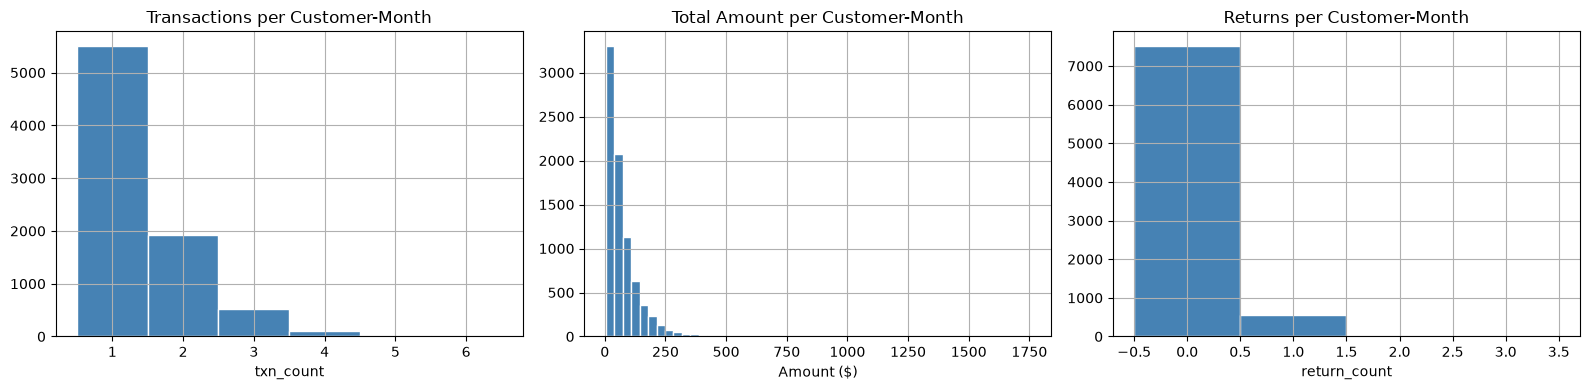

In [6]:
for col, label in [('txn_count', 'Transactions per Customer-Month'),
                   ('total_amount', 'Total Amount per Customer-Month'),
                   ('return_count', 'Returns per Customer-Month')]:
    d = profile_distribution(agg[col])
    print(f'=== {label} ===')
    for k, v in d.items():
        print(f'  {k}: {v}')
    print()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
agg['txn_count'].hist(bins=range(1, 8), ax=axes[0], color='steelblue', edgecolor='white', align='left')
axes[0].set_title('Transactions per Customer-Month')
axes[0].set_xlabel('txn_count')

agg['total_amount'].hist(bins=50, ax=axes[1], color='steelblue', edgecolor='white')
axes[1].set_title('Total Amount per Customer-Month')
axes[1].set_xlabel('Amount ($)')

agg['return_count'].hist(bins=range(0, 5), ax=axes[2], color='steelblue', edgecolor='white', align='left')
axes[2].set_title('Returns per Customer-Month')
axes[2].set_xlabel('return_count')
plt.tight_layout()
plt.show()


## 6. Category, Channel & Region Breakdowns

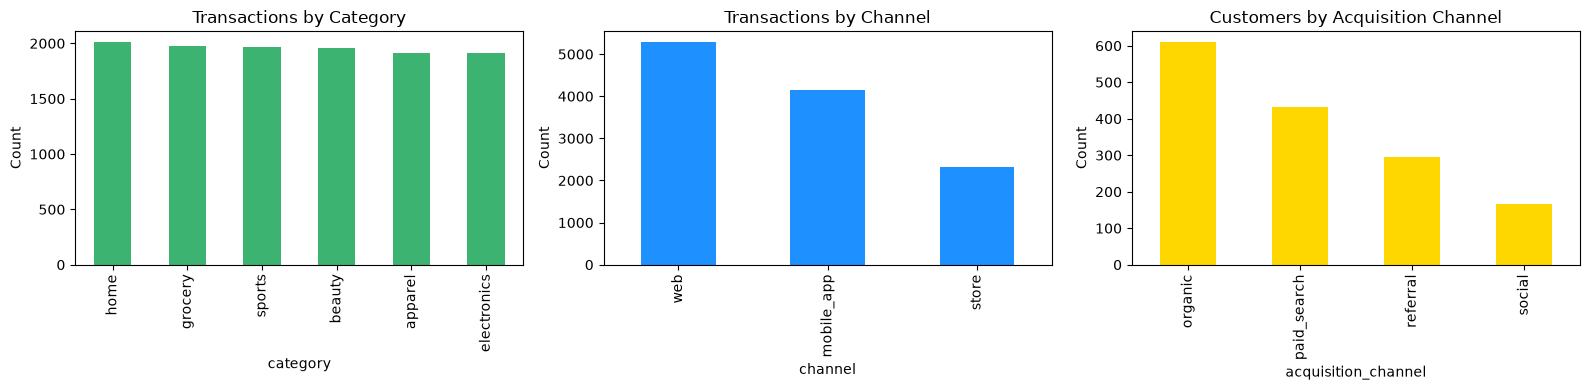

Category counts: {'home': 2008, 'grocery': 1979, 'sports': 1969, 'beauty': 1958, 'apparel': 1917, 'electronics': 1911}
Channel counts: {'web': 5278, 'mobile_app': 4146, 'store': 2318}
Acquisition channel counts: {'organic': 609, 'paid_search': 431, 'referral': 295, 'social': 165}
Region counts: {'east': 385, 'north': 381, 'west': 380, 'south': 354}
Returns: 591 / 11742 = 5.0%


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

txn['category'].value_counts().plot(kind='bar', ax=axes[0], color='mediumseagreen')
axes[0].set_title('Transactions by Category')
axes[0].set_ylabel('Count')

txn['channel'].value_counts().plot(kind='bar', ax=axes[1], color='dodgerblue')
axes[1].set_title('Transactions by Channel')
axes[1].set_ylabel('Count')

cust['acquisition_channel'].value_counts().plot(kind='bar', ax=axes[2], color='gold')
axes[2].set_title('Customers by Acquisition Channel')
axes[2].set_ylabel('Count')

plt.tight_layout()
plt.show()

print('Category counts:', txn['category'].value_counts().to_dict())
print('Channel counts:', txn['channel'].value_counts().to_dict())
print('Acquisition channel counts:', cust['acquisition_channel'].value_counts().to_dict())
print('Region counts:', cust['region'].value_counts().to_dict())
print(f'Returns: {txn["is_returned"].sum()} / {len(txn)} = {txn["is_returned"].mean()*100:.1f}%')


## 7. Churn Rate Analysis

### Overall Churn Rate

**13.47%** (202 of 1,500 customers). This is a moderate class imbalance.

Churned: 202 / 1500 = 13.47%


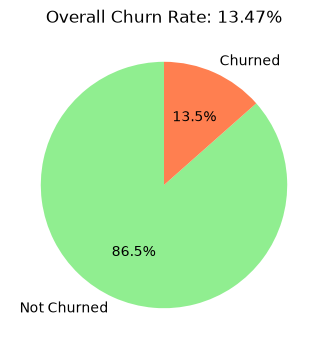

In [8]:
churn_rate = cust['churned'].mean()
n_churned = cust['churned'].sum()
print(f'Churned: {n_churned} / {len(cust)} = {churn_rate*100:.2f}%')

fig, ax = plt.subplots(figsize=(6, 4))
ax.pie([1.0 - churn_rate, churn_rate],
       labels=['Not Churned', 'Churned'],
       autopct='%1.1f%%', startangle=90,
       colors=['lightgreen', 'coral'])
ax.set_title(f'Overall Churn Rate: {churn_rate*100:.2f}%')
plt.show()


### Churn Rate by Acquisition Channel (NOT significant: p=0.12)

Despite observable differences in raw rates, acquisition channel is **not statistically significant** (chi-square test).

                     Count  Churn Rate %
acquisition_channel                     
organic                609         15.27
social                 165         14.55
referral               295         13.90
paid_search            431         10.21


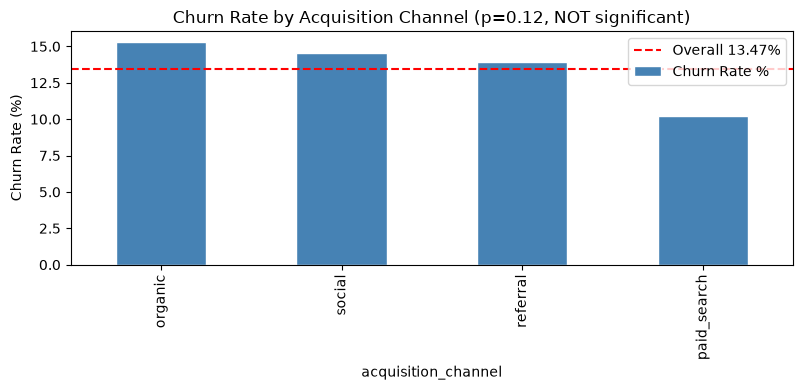

In [9]:
cc = cust.groupby('acquisition_channel')['churned'].agg(['count', 'mean'])
cc['mean'] = cc['mean'] * 100
cc.columns = ['Count', 'Churn Rate %']
cc = cc.sort_values('Churn Rate %', ascending=False)
print(cc.round(2))

fig, ax = plt.subplots(figsize=(8, 4))
cc['Churn Rate %'].plot(kind='bar', ax=ax, color='steelblue', edgecolor='white')
ax.set_title('Churn Rate by Acquisition Channel (p=0.12, NOT significant)')
ax.set_ylabel('Churn Rate (%)')
ax.axhline(y=13.47, color='red', ls='--', label='Overall 13.47%')
ax.legend()
plt.tight_layout()
plt.show()


### Churn Rate by Region (NOT significant: p=0.29)

Region is also **not statistically significant** despite east being slightly higher.

        Count  Churn Rate %
region                     
east      385         16.36
south     354         12.71
west      380         12.37
north     381         12.34


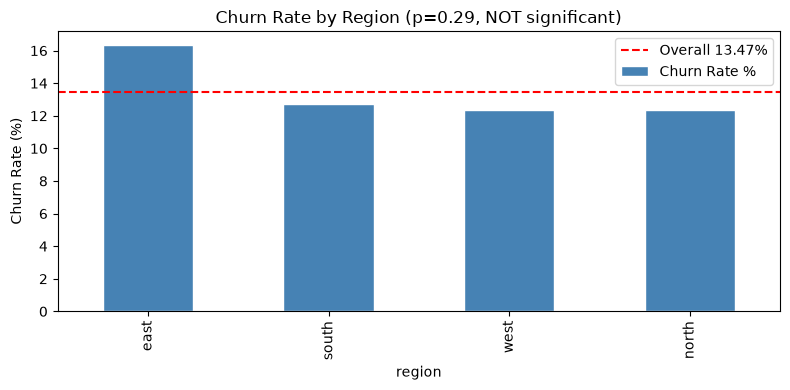

In [10]:
rc = cust.groupby('region')['churned'].agg(['count', 'mean'])
rc['mean'] = rc['mean'] * 100
rc.columns = ['Count', 'Churn Rate %']
rc = rc.sort_values('Churn Rate %', ascending=False)
print(rc.round(2))

fig, ax = plt.subplots(figsize=(8, 4))
rc['Churn Rate %'].plot(kind='bar', ax=ax, color='steelblue', edgecolor='white')
ax.set_title('Churn Rate by Region (p=0.29, NOT significant)')
ax.set_ylabel('Churn Rate (%)')
ax.axhline(y=13.47, color='red', ls='--', label='Overall 13.47%')
ax.legend()
plt.tight_layout()
plt.show()


### Churn Rate by Preferred Transaction Channel (significant: p < 0.001)

The `none` group represents zero-activity customers. Among active customers, store shoppers churn slightly more than web/mobile.

channel
mobile_app      9.13
none          100.00
store          10.95
web             7.80
Name: churned, dtype: float64


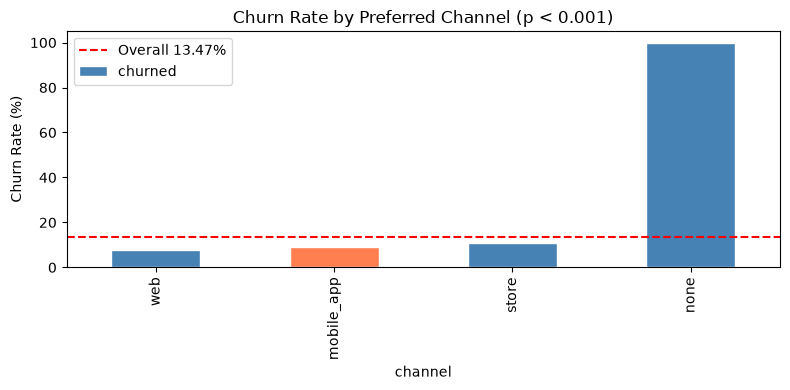

In [11]:
top_channel = (
    txn.groupby(['customer_id', 'channel'])
    .size().reset_index(name='cnt')
    .sort_values('cnt', ascending=False)
    .groupby('customer_id')
    .first().reset_index()[['customer_id', 'channel']]
)
merged = cust[['customer_id', 'churned']].merge(
    top_channel, on='customer_id', how='left')
merged['channel'] = merged['channel'].fillna('none')

tc = merged.groupby('channel')['churned'].mean() * 100
print(tc.round(2))

fig, ax = plt.subplots(figsize=(8, 4))
colors = ['coral' if v > 50 else 'steelblue' for v in tc.values]
tc.sort_values().plot(kind='bar', ax=ax, color=colors, edgecolor='white')
ax.set_title("Churn Rate by Preferred Channel (p < 0.001)")
ax.set_ylabel('Churn Rate (%)')
ax.axhline(y=13.47, color='red', ls='--', label='Overall 13.47%')
ax.legend()
plt.tight_layout()
plt.show()


### Churn Rate by Preferred Category (significant: p < 0.001)

Electronics shoppers have the highest churn rate and grocery shoppers the lowest among active customers.

category
none           100.00
electronics     12.72
apparel          9.56
beauty           8.88
sports           7.92
home             7.58
grocery          3.98
Name: churned, dtype: float64


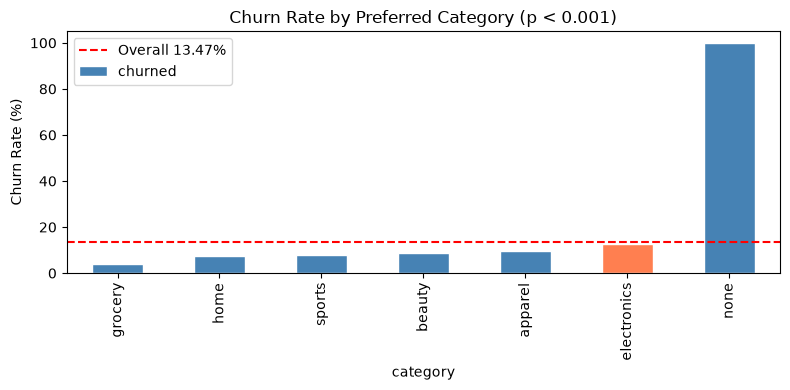

In [12]:
top_cat = (
    txn.groupby(['customer_id', 'category'])
    .size().reset_index(name='cnt')
    .sort_values('cnt', ascending=False)
    .groupby('customer_id')
    .first().reset_index()[['customer_id', 'category']]
)
merged = cust[['customer_id', 'churned']].merge(
    top_cat, on='customer_id', how='left')
merged['category'] = merged['category'].fillna('none')

tc = merged.groupby('category')['churned'].mean() * 100
print(tc.sort_values(ascending=False).round(2))

fig, ax = plt.subplots(figsize=(8, 4))
colors = ['coral' if v > 50 else 'steelblue' for v in tc.values]
tc.sort_values().plot(kind='bar', ax=ax, color=colors, edgecolor='white')
ax.set_title("Churn Rate by Preferred Category (p < 0.001)")
ax.set_ylabel('Churn Rate (%)')
ax.axhline(y=13.47, color='red', ls='--', label='Overall 13.47%')
ax.legend()
plt.tight_layout()
plt.show()


## 8. Hypothesis Test Results

All tests run against the raw data. Continuous-driver tests (avg_monthly_spend, total_amount) use data **outside** the 90-day leakage window (before 2026-05-03).

| Driver | Test | p-value | Significant? | Effect |
|---|---|---|---|---|
| acquisition_channel | Chi-square | 0.120 | **No** | organic 15.3%, paid_search 10.2%, referral 13.9%, social 14.5% |
| region | Chi-square | 0.289 | **No** | east 16.4%, south 12.7%, west 12.4%, north 12.3% |
| txn_channel | Chi-square | < 0.001 | **Yes** | no-txn 100%; store 10.9%, mobile 9.1%, web 7.8% |
| category | Chi-square | < 0.001 | **Yes** | electronics 12.7%, grocery 4.0%, others 7-10% |
| avg_monthly_spend | Mann-Whitney U | < 0.001 | **Yes** | Churned $40.23 vs Not $57.19 |
| total_amount | Mann-Whitney U | < 0.001 | **Yes** | Churned $188.73 vs Not $286.91 |
| return_count | Mann-Whitney U | 0.001 | **Yes** | Churned 0.20 vs Not 0.42 |
| days_since_last_txn | Mann-Whitney U | < 0.001 | **Yes (LEAKAGE)** | Churned median 168d vs Not 23d |

In [13]:
tests = {
    'acquisition_channel': hypothesis_acquisition_channel(cust),
    'region': hypothesis_region(cust),
    'txn_channel': hypothesis_txn_channel(cust, txn),
    'category': hypothesis_category(cust, txn),
    'avg_monthly_spend': hypothesis_avg_monthly_spend(cust, txn),
    'total_amount': hypothesis_total_amount(cust, txn),
    'return_count': hypothesis_return_count(cust, txn),
    'days_since_last_txn': hypothesis_days_since_last_txn(cust, txn),
}

for name, r in tests.items():
    sig = 'SIGNIFICANT' if r['p_value'] is not None and r['p_value'] < 0.05 else 'NOT SIGNIFICANT'
    p_str = f'{r["p_value"]:.6f}' if r['p_value'] is not None else 'N/A'
    note = f' [{r["note"]}]' if r.get('note') else ''
    print(f'{name:30s} | p={p_str:12s} | {sig:20s}{note}')
    print(f'  Statistic: {r["statistic"]}')
    print(f'  Effect: {r["effect_size"]}')
    print()


acquisition_channel            | p=0.119725     | NOT SIGNIFICANT     
  Statistic: 5.8387
  Effect: Churn rates: {'paid_search': 0.10208816705336426, 'referral': 0.13898305084745763, 'social': 0.14545454545454545, 'organic': 0.15270935960591134}

region                         | p=0.288915     | NOT SIGNIFICANT     
  Statistic: 3.7571
  Effect: Churn rates: {'north': 0.12335958005249344, 'west': 0.12368421052631579, 'south': 0.1271186440677966, 'east': 0.16363636363636364}

txn_channel                    | p=0.000000     | SIGNIFICANT         
  Statistic: 551.4006
  Effect: Churn by preferred channel: {'web': 0.07803121248499399, 'mobile_app': 0.09131403118040089, 'store': 0.10948905109489052, 'none': 1.0}

category                       | p=0.000000     | SIGNIFICANT         
  Statistic: 558.1593
  Effect: Churn by top category: {'grocery': 0.03982300884955752, 'home': 0.07582938388625593, 'sports': 0.07920792079207921, 'beauty': 0.0888030888030888, 'apparel': 0.09556313993174062,

## 9. Monthly Transaction-Volume Trend

Monthly transaction volume grew **8.11×** over 30 months. This severe non-stationarity mandates a time-based train/test split.

Total months: 30
Date range: 2024-02-01 to 2026-07-01
First-half avg txn/month: 85.9
Second-half avg txn/month: 696.9
Growth ratio: 8.11x


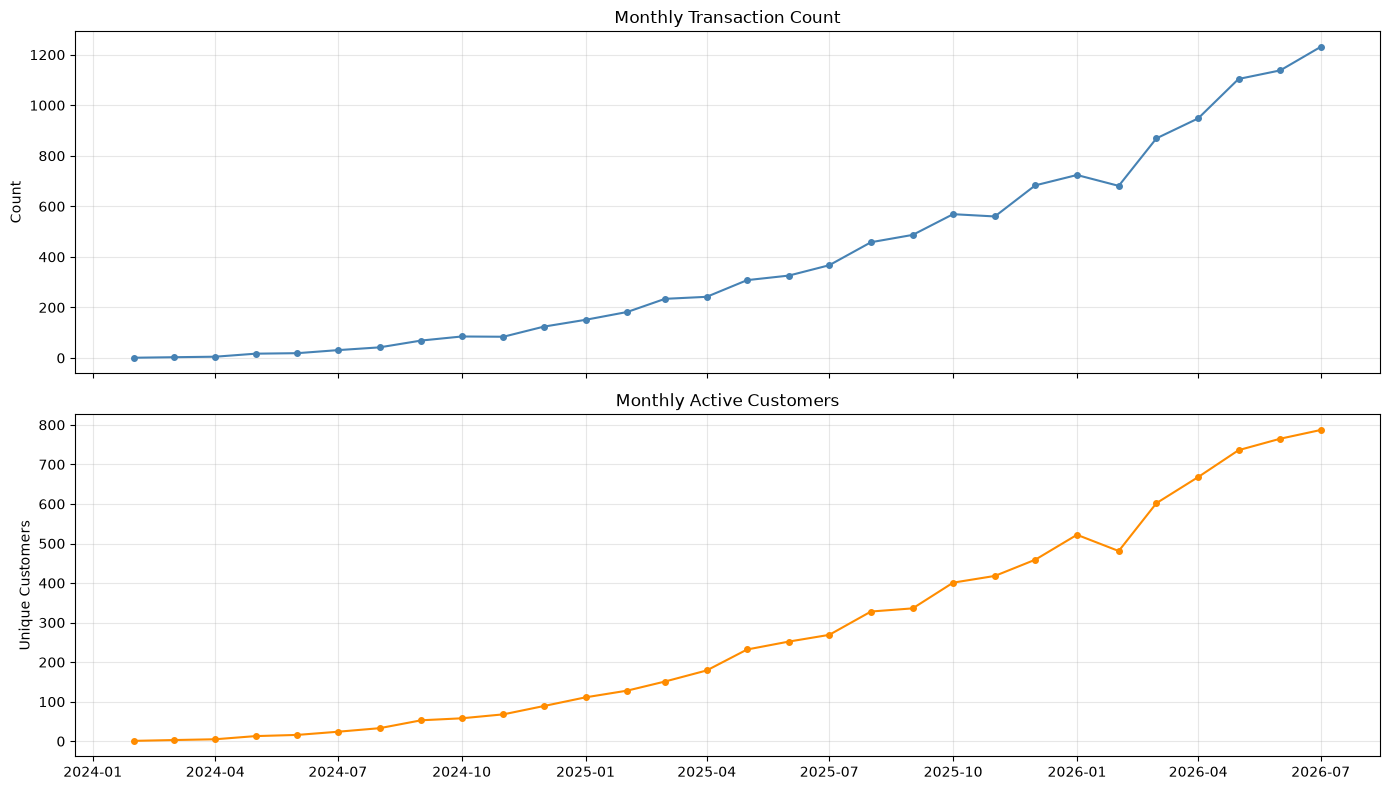

In [14]:
mv = monthly_volume_trend(txn)
td = trend_direction(txn)
print(f'Total months: {td["total_months"]}')
print(f'Date range: {td["date_range"][0].date()} to {td["date_range"][1].date()}')
print(f'First-half avg txn/month: {td["first_half_avg_txn_per_month"]}')
print(f'Second-half avg txn/month: {td["second_half_avg_txn_per_month"]}')
print(f'Growth ratio: {td["growth_ratio"]}x')

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

axes[0].plot(mv['month'], mv['txn_count'], marker='o', color='steelblue', markersize=4, linewidth=1.5)
axes[0].set_title('Monthly Transaction Count')
axes[0].set_ylabel('Count')
axes[0].grid(True, alpha=0.3)

axes[1].plot(mv['month'], mv['unique_customers'], marker='o', color='darkorange', markersize=4, linewidth=1.5)
axes[1].set_title('Monthly Active Customers')
axes[1].set_ylabel('Unique Customers')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## 10. Multi-Source Agreement

Reaggregating `transactions.db` to customer-month and comparing against `transactions_monthly_agg.parquet` shows **perfect agreement for all months except July 2026**, where the parquet is missing ~237 transactions. The row-level DB should be used as the source of truth.

Rows in reagg (from DB):  8188
Rows in agg (parquet):    8086
Rows in both:             8086
Rows only in reagg:       102
Rows only in agg:         0
Abs diff txn_count sum:   127
Abs diff total_amount:    $6805.25
Abs diff return_count:    5


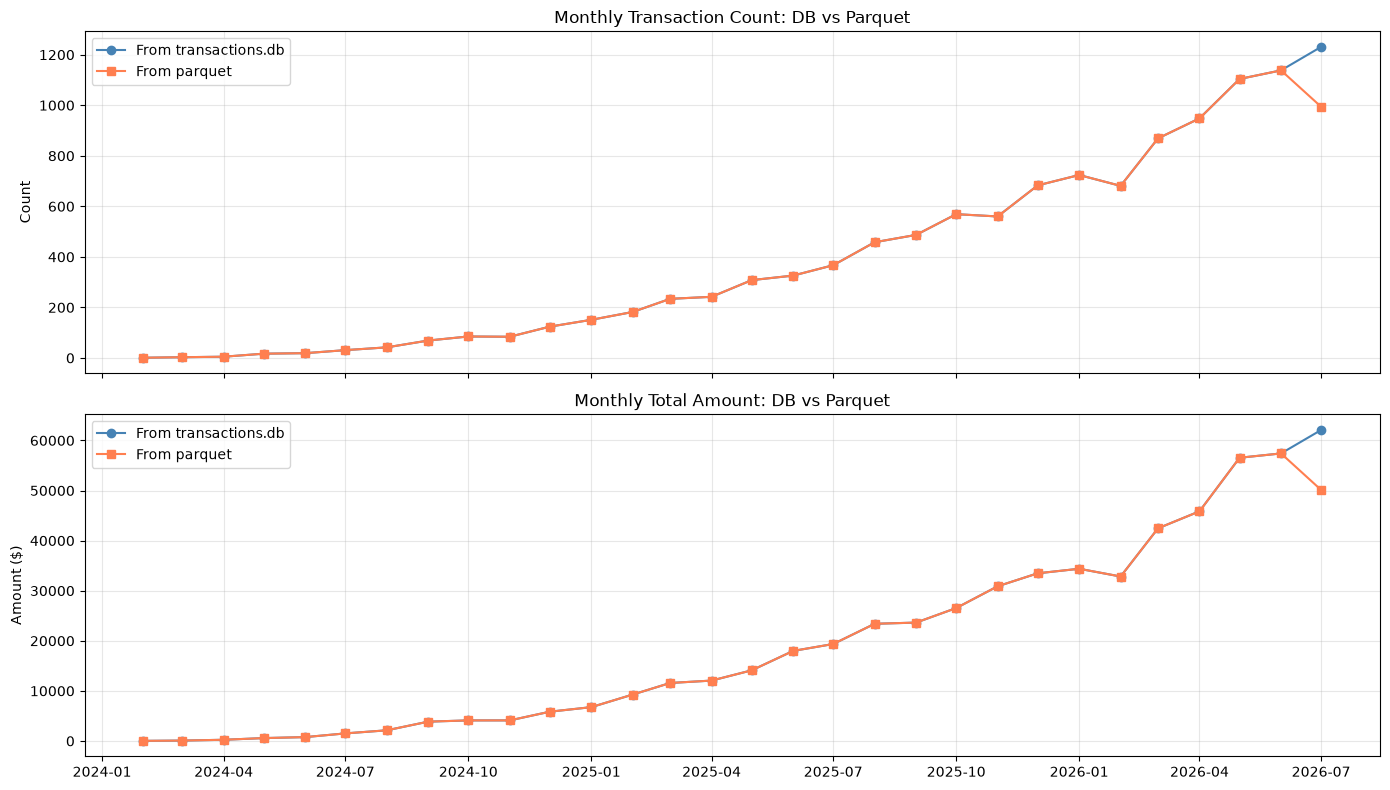

In [15]:
ms = compare_row_level_vs_monthly_agg(txn, agg)
print(f'Rows in reagg (from DB):  {ms["total_rows_reaggregated"]}')
print(f'Rows in agg (parquet):    {ms["total_rows_agg"]}')
print(f'Rows in both:             {ms["rows_in_both"]}')
print(f'Rows only in reagg:       {ms["rows_only_in_reaggregated"]}')
print(f'Rows only in agg:         {ms["rows_only_in_agg"]}')
print(f'Abs diff txn_count sum:   {ms["abs_diff_txn_count_sum"]}')
print(f'Abs diff total_amount:    ${ms["abs_diff_total_amount_sum"]}')
print(f'Abs diff return_count:    {ms["abs_diff_return_count_sum"]}')

comp = ms['monthly_comparison']
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

axes[0].plot(comp['txn_month'], comp['txn_count_reagg'],
             marker='o', label='From transactions.db', color='steelblue', linewidth=1.5)
axes[0].plot(comp['txn_month'], comp['txn_count_agg'],
             marker='s', label='From parquet', color='coral', linewidth=1.5)
axes[0].set_title('Monthly Transaction Count: DB vs Parquet')
axes[0].set_ylabel('Count')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(comp['txn_month'], comp['total_amount_reagg'],
             marker='o', label='From transactions.db', color='steelblue', linewidth=1.5)
axes[1].plot(comp['txn_month'], comp['total_amount_agg'],
             marker='s', label='From parquet', color='coral', linewidth=1.5)
axes[1].set_title('Monthly Total Amount: DB vs Parquet')
axes[1].set_ylabel('Amount ($)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## 11. Leakage Checks

The as-of date for the dataset is **2026-08-01**. The churn label is defined as “no purchase in the 90 days before this date,” making **2026-05-03** the leakage cutoff. Any feature derived from transactions after this date is definitionally circular with the label.

In [16]:
lc = check_no_post_as_of_rows_used(txn)
print(f'As-of date: {lc["as_of_date"].date()}')
print(f'Leakage cutoff (90 days prior): {lc["leakage_cutoff"].date()}')
print(f'Max txn timestamp in data: {lc["max_txn_timestamp_in_data"]}')
print(f'Rows after as-of date: {lc["rows_after_as_of_date"]}')
print(f'Rows within trailing 90d window: {lc["rows_within_trailing_90d_window"]}',
      f'({lc["rows_within_trailing_90d_window"]/len(txn)*100:.1f}%)')
print(f'Pass as-of check: {lc["pass_as_of_check"]}')
print()

ld = flag_label_circular_drivers()
print(f'Leakage-tainted drivers: {ld["leakage_tainted_drivers"]}')
print()
print('--- days_since_last_txn: documenting the circularity ---')
r = hypothesis_days_since_last_txn(cust, txn)
print(f'  Test statistic: {r["statistic"]}')
print(f'  p-value: {r["p_value"]}')
print(f'  Effect: {r["effect_size"]}')
print(f'  Note: {r["note"]}')


As-of date: 2026-08-01
Leakage cutoff (90 days prior): 2026-05-03
Max txn timestamp in data: 2026-07-31 23:50:29.001075447
Rows after as-of date: 0
Rows within trailing 90d window: 3416 (29.1%)
Pass as-of check: True

Leakage-tainted drivers: ['days_since_last_txn', 'total_spend_trailing_90d', 'txn_count_trailing_90d', 'recency']

--- days_since_last_txn: documenting the circularity ---
  Test statistic: 262196.0
  p-value: 0.0
  Effect: Median churned=168d, not_churned=23d (diff=145d)
  Note: LEAKAGE CHECK — this variable is circular with the label definition


## 12. Summary & Model-Family Recommendation

### Key verified findings:

1. **13.47% churn rate** (202/1500) — moderate class imbalance

2. **81 zero-activity customers**, all churned — separate behavioral cohort, not imputable into transaction-based models

3. **acquisition_channel** and **region** are NOT significant churn drivers (p > 0.05) — the Stage 0 draft over-interpreted raw rate differences

4. **Spend-based features** are significant: churned customers spend less ($40 vs $57 avg monthly, $189 vs $287 lifetime)

5. **days_since_last_txn** shows a massive effect (168d vs 23d median) — this is **label leakage**, not prediction; strictly excluded from modeling

6. **8.11× growth** in monthly volume over 30 months — non-stationarity requires time-based train/test split

7. **Multi-source disagreement** only in July 2026 — the parquet snapshot missed the final month’s data (237 transactions)

8. **return_count**: churned customers return less (0.20 vs 0.42) — a small effect in the unexpected direction

### Model recommendation: Gradient Boosted Trees (XGBoost / LightGBM)

**Justification from verified data characteristics:**

1. **Heavily right-skewed amount features** (skew=6.02) — trees handle these natively, no log-transform needed
2. **Mixed categorical + numeric features** — trees handle both without one-hot encoding 17+ dummy variables
3. **Non-linear interaction effects** (channel × region combinations show varying churn rates from 8.8% to 22.9%)
4. **Built-in class-weight support** for the 13.5% imbalance

**Exclude from modeling:**
• All trailing-90-day features (days_since_last_txn, spend, txn count) — definitional leakage
• Zero-activity cohort from transaction-based models — treat as separate segment

**Evaluation:** Use F1 / Precision / Recall as primary metrics (raw accuracy ~86.5% is misleading). Time-based train/validation/test split required.